In [1]:
# setup cell
%pip install -q libpysal esda splot mapclassify contextily

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify

DATA_BASE_P2 = "https://raw.githubusercontent.com/pjbitterman/KSU_x9076/main/data/part2"
tracts = gpd.read_file(f"{DATA_BASE_P2}/cuyahoga_tracts_acs.gpkg")

print("Number of tracts:", len(tracts))
print("Missing median gross rent:", tracts["median_gross_rent"].isna().sum())

Number of tracts: 428
Missing median gross rent: 31


In [3]:
# Use the land tracts to set the map limits
land = tracts[tracts["ALAND"] > 0]
minx, miny, maxx, maxy = land.total_bounds

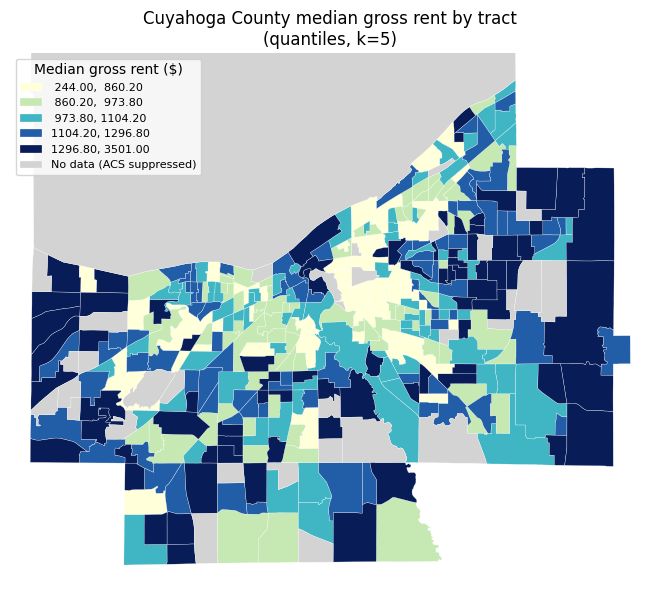

In [4]:
# Map1:Quantile
fig, ax = plt.subplots(figsize=(9, 7))
tracts.plot(
    column="median_gross_rent",
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    legend=True,
    legend_kwds={"title": "Median gross rent ($)", "loc": "upper left", "fontsize": 8},
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "No data (ACS suppressed)"},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)
ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County median gross rent by tract\n(quantiles, k=5)")
fig.savefig("rent_quantiles.png", dpi=200, bbox_inches="tight")
plt.show()


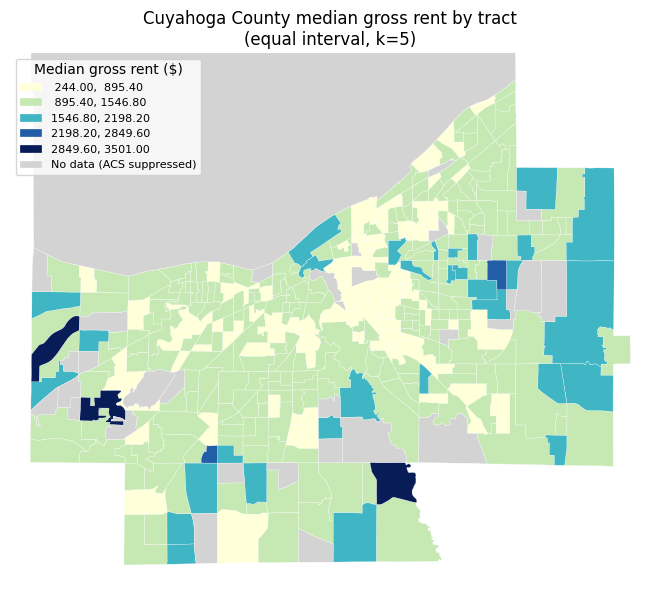

In [5]:
#Map 2: Equal Interval
fig, ax = plt.subplots(figsize=(9, 7))
tracts.plot(
    column="median_gross_rent",
    scheme="equal_interval",
    k=5,
    cmap="YlGnBu",
    legend=True,
    legend_kwds={"title": "Median gross rent ($)", "loc": "upper left", "fontsize": 8},
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "No data (ACS suppressed)"},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)
ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County median gross rent by tract\n(equal interval, k=5)")
fig.savefig("rent_equal_interval.png", dpi=200, bbox_inches="tight")
plt.show()


In [6]:
#bin counts
rent = tracts["median_gross_rent"].dropna()

quantiles = mapclassify.Quantiles(rent, k=5)
equal_interval = mapclassify.EqualInterval(rent, k=5)

print("Quantiles counts:", list(quantiles.counts))
print("Equal interval counts:", list(equal_interval.counts))
print("Quantiles upper limits:", quantiles.bins)
print("Equal interval upper limits:", equal_interval.bins)


Quantiles counts: [np.int64(80), np.int64(79), np.int64(79), np.int64(79), np.int64(80)]
Equal interval counts: [np.int64(108), np.int64(253), np.int64(31), np.int64(2), np.int64(3)]
Quantiles upper limits: [ 860.2  973.8 1104.2 1296.8 3501. ]
Equal interval upper limits: [ 895.4 1546.8 2198.2 2849.6 3501. ]


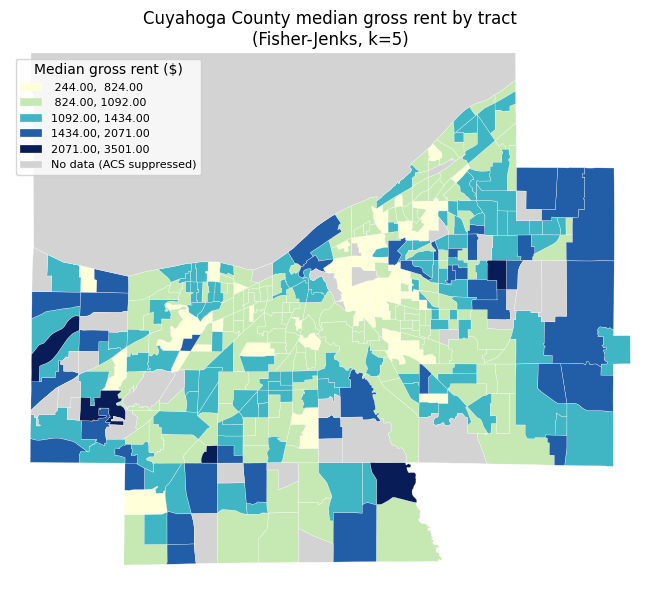

In [7]:
# Map 3: Fisher Jenks
fig, ax = plt.subplots(figsize=(9, 7))
tracts.plot(
    column="median_gross_rent",
    scheme="fisher_jenks",
    k=5,
    cmap="YlGnBu",
    legend=True,
    legend_kwds={"title": "Median gross rent ($)", "loc": "upper left", "fontsize": 8},
    missing_kwds={"color": "lightgrey", "edgecolor": "white", "label": "No data (ACS suppressed)"},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)
ax.set_xlim(minx - 0.02, maxx + 0.02)
ax.set_ylim(miny - 0.02, maxy + 0.02)
ax.set_axis_off()
ax.set_title("Cuyahoga County median gross rent by tract\n(Fisher-Jenks, k=5)")
fig.savefig("rent_fisher_jenks.png", dpi=200, bbox_inches="tight")
plt.show()


In [8]:
fisher_jenks = mapclassify.FisherJenks(rent, k=5)
print("Fisher-Jenks counts:", list(fisher_jenks.counts))
print("Fisher-Jenks upper limits:", fisher_jenks.bins)


Fisher-Jenks counts: [np.int64(61), np.int64(171), np.int64(120), np.int64(40), np.int64(5)]
Fisher-Jenks upper limits: [ 824. 1092. 1434. 2071. 3501.]


## Task 1: Comparing quantiles and equal interval

Both maps use the same rent values, but the tracts look different because the class breaks change. Quantiles puts 79 or 80 tracts in each class, while equal interval puts 108, 253, 31, 2, and 3 tracts in its classes. In parts of the western and eastern county, several tracts look dark blue with quantiles but much lighter with equal interval. Equal interval could make a reader think that high rent is very uncommon because only 5 tracts fall in its two highest classes, while the quantiles map places 80 tracts in its highest class. I find equal interval more misleading here because it groups most tracts into one class and hides differences between their rent values.

## Task 2: When I would use Fisher-Jenks

I would use Fisher-Jenks when the rent values form groups, because it puts similar values together instead of forcing equal numbers of tracts or equal-width ranges.